# Подбор датасетов для двух задач регрессии


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter, ScalarFormatter
import numpy as np
import pandas as pd

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "grid.color": "#E0E7EF",
})

PENGUINS_URL = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
ABALONE_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/abalone.data"

def read_data(filename, url, **kwargs):
    path = Path("data") / filename
    return pd.read_csv(path if path.is_file() else url, **kwargs)

## 1. Две регрессии для двух групп · Palmer Penguins

В наборе 344 измерения пингвинов с островов архипелага Палмера за 2007–2009 годы. Возьмём длину клюва и его глубину в миллиметрах. После удаления двух строк с пропусками получаем две основные группы — Adelie (151 наблюдение) и Gentoo (123 наблюдения). Ещё 68 пингвинов Chinstrap представляют вид вне этих групп.


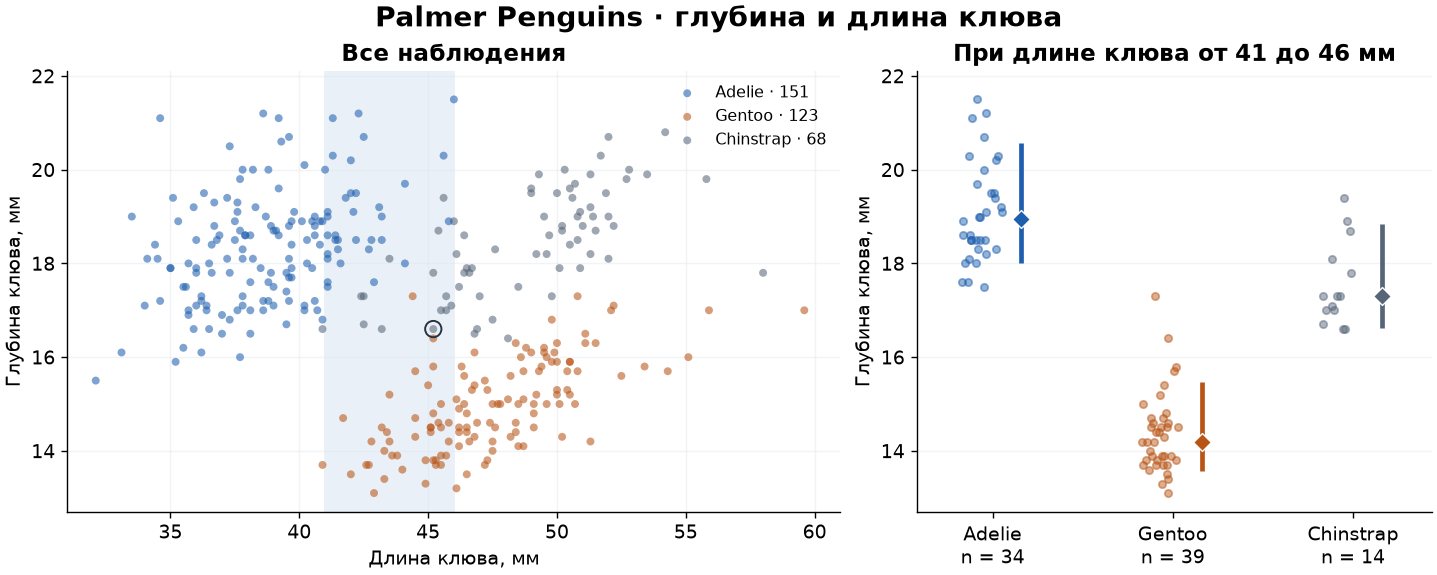

In [2]:
penguins = read_data("penguins.csv", PENGUINS_URL).dropna(
    subset=["bill_length_mm", "bill_depth_mm"]
)
length = "bill_length_mm"
depth = "bill_depth_mm"
colors = {"Adelie": "#1D5EAE", "Gentoo": "#B85415", "Chinstrap": "#566578"}
groups = ["Adelie", "Gentoo", "Chinstrap"]
overlap = penguins.loc[penguins[length].between(41, 46)]

fig, (ax, spread) = plt.subplots(
    1, 2, figsize=(11.5, 4.6), layout="constrained",
    gridspec_kw={"width_ratios": [1.5, 1]},
)
fig.suptitle("Palmer Penguins · глубина и длина клюва", fontsize=16, fontweight="bold")
ax.axvspan(41, 46, color="#EAF0F7", zorder=0)

for species in reversed(groups):
    points = penguins.loc[penguins["species"].eq(species)]
    ax.scatter(
        points[length], points[depth], s=21, color=colors[species],
        alpha=0.57, edgecolors="none", label=f"{species} · {len(points)}",
    )

ax.scatter(45.2, 16.6, s=88, facecolors="none", edgecolors="#253142", linewidth=1.1)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper right", frameon=False, fontsize=9)
ax.set(
    title="Все наблюдения", xlabel="Длина клюва, мм",
    ylabel="Глубина клюва, мм", xlim=(31, 61), ylim=(12.7, 22.1),
)
ax.grid(alpha=0.46)

rng = np.random.default_rng(17)
tick_labels = []
for index, species in enumerate(groups):
    values = overlap.loc[overlap["species"].eq(species), depth]
    p10, median, p90 = values.quantile([0.1, 0.5, 0.9])
    positions = index + rng.uniform(-0.17, 0.05, size=len(values))
    spread.scatter(positions, values, s=18, color=colors[species], alpha=0.48)
    spread.vlines(index + 0.16, p10, p90, color=colors[species], linewidth=2.7)
    spread.scatter(index + 0.16, median, s=53, marker="D", color=colors[species],
                   edgecolor="white", linewidth=0.8, zorder=3)
    tick_labels.append(f"{species}\nn = {len(values)}")

spread.set(
    title="При длине клюва от 41 до 46 мм",
    ylabel="Глубина клюва, мм", xlim=(-0.42, 2.44), ylim=ax.get_ylim(),
)
spread.set_xticks(range(len(groups)), tick_labels)
spread.grid(axis="y", alpha=0.46)
plt.show()

## 2. Нелинейная зависимость · Abalone

В наборе 4 177 измерений морских ушек. Возьмём максимальную длину раковины  и полную массу. На графиках используем значения из файла UCI в опубликованном масштабе.


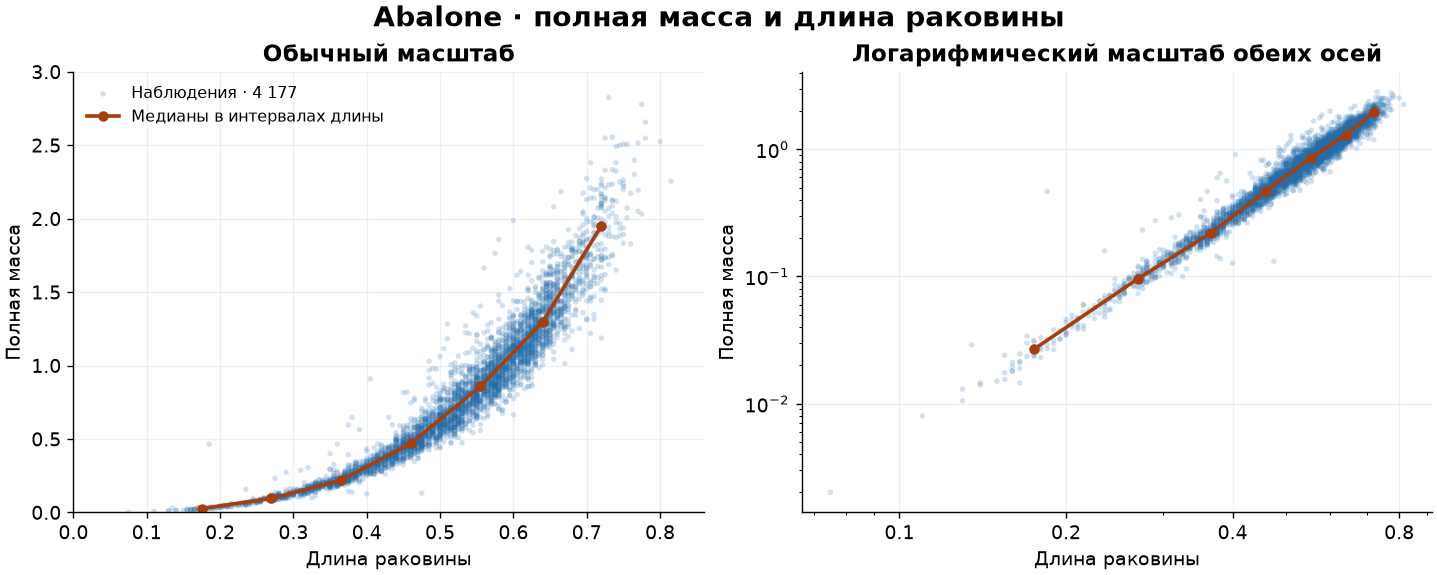

In [3]:
columns = [
    "sex", "length", "diameter", "height", "whole_weight", "shucked_weight",
    "viscera_weight", "shell_weight", "rings",
]
abalone = read_data("abalone.data", ABALONE_URL, header=None, names=columns)

# Для устойчивых медиан показываем интервалы длины с 10 и более наблюдениями.
length_bins = pd.cut(abalone["length"], bins=np.linspace(0, 0.9, 10))
medians = (
    abalone.groupby(length_bins, observed=True)
    .agg(n=("length", "size"), length=("length", "median"), mass=("whole_weight", "median"))
    .loc[lambda bins: bins["n"].ge(10)]
)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), layout="constrained")
fig.suptitle("Abalone · полная масса и длина раковины", fontsize=16, fontweight="bold")
for ax in axes:
    ax.scatter(
        abalone["length"], abalone["whole_weight"], s=10, color="#246CAA",
        alpha=0.20, edgecolors="none", label=f"Наблюдения · {len(abalone):,}".replace(",", " "),
    )
    ax.plot(
        medians["length"], medians["mass"], "o-", color="#A63F0B",
        linewidth=2.1, markersize=5, label="Медианы в интервалах длины",
    )
    ax.set(xlabel="Длина раковины", ylabel="Полная масса")
    ax.grid(alpha=0.6)

axes[0].set(title="Обычный масштаб", xlim=(0, 0.86), ylim=(0, 3.0))
axes[1].set(title="Логарифмический масштаб обеих осей", xscale="log", yscale="log")
axes[1].set_xticks([0.1, 0.2, 0.4, 0.8])
axes[1].xaxis.set_major_formatter(ScalarFormatter())
axes[1].xaxis.set_minor_formatter(NullFormatter())
axes[0].legend(loc="upper left", frameon=False, fontsize=9)
plt.show()